**Causal Effects of Canopy Management on Sangiovese grapes**

Pedico Simone


 The natural language interpretation for each query, and other details are discussed in the PDF file that I have submitted with this notebook.

# Imports and set-up

In [ ]:
import numpy as np
import pandas as pd
import networkx as nx
from google.colab import files
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from sklearn.preprocessing import LabelEncoder

In [ ]:
# loading files (sangiovese.csv and sangiovese.gml)
uploaded = files.upload()

Saving sangiovese.csv to sangiovese.csv
Saving sangiovese.gml to sangiovese.gml


In [ ]:
# sangiovese.csv
df = pd.read_csv('sangiovese.csv')
display(df.head())

,Treatment,SproutN,BunchN,GrapeW,WoodW,SPAD06,NDVI06,SPAD08,NDVI08,Acid,Potass,Brix,pH,Anthoc,Polyph
0,T4b,0.035097,-0.490884,-0.621906,-0.012823,-0.215930,-0.169575,-0.090999,0.090477,0.332058,-0.136271,-0.042447,-0.051835,0.179822,-0.043765
1,T2a,0.132832,0.563280,0.751732,0.295413,0.078903,0.100730,0.071215,0.090093,-0.128861,-0.150137,-0.006624,0.031027,-0.327344,-0.114005
2,T6b,0.075647,-0.674892,-0.146740,0.115401,-0.046764,0.146192,0.128560,0.209104,-0.152679,-0.054454,0.068229,0.016342,-0.065735,0.022909
3,T3b,-0.025307,-0.209328,-0.149472,-0.592625,-0.079386,-0.102390,-0.123381,-0.092219,-0.009640,-0.135796,-0.003187,-0.011927,0.018778,0.236052
4,T1b,0.120625,0.453594,0.443389,-0.080260,0.040797,0.034930,-0.141698,-0.162745,0.082526,-0.072774,-0.023142,-0.038200,0.206323,0.212407


Grafo caricato con 15 nodi e 55 archi.


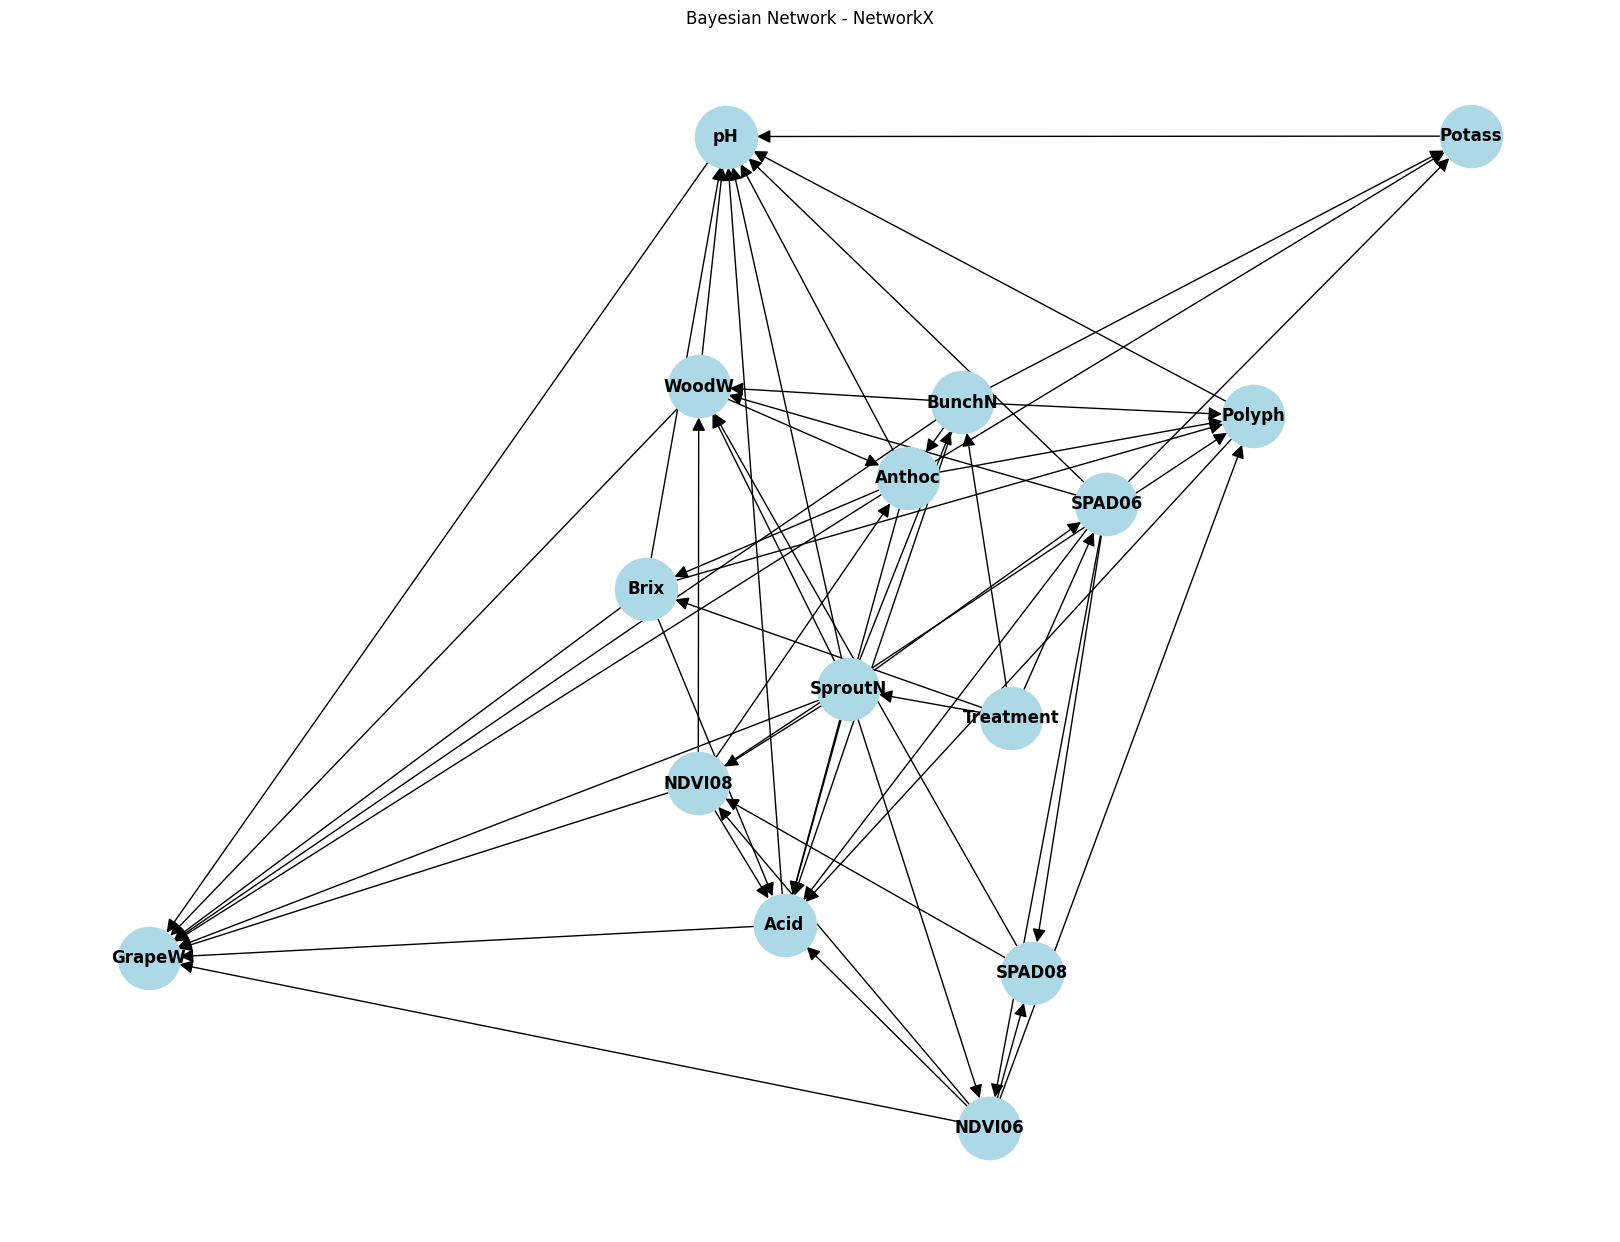

In [ ]:
# sangiovese.gml
G = nx.read_gml('sangiovese.gml')

plt.figure(figsize=(16, 12))
pos = nx.spring_layout(G, seed=42)
nx.draw(G, pos, with_labels=True, node_color='lightblue', node_size=2000, font_size=12, arrowsize=20, font_weight='bold')

plt.title("Graph")
plt.show()

In [ ]:
edges = list(G.edges())
print(edges)

[('Treatment', 'SproutN'), ('Treatment', 'BunchN'), ('Treatment', 'SPAD06'), ('Treatment', 'Brix'), ('SproutN', 'BunchN'), ('SproutN', 'GrapeW'), ('SproutN', 'WoodW'), ('SproutN', 'SPAD06'), ('SproutN', 'NDVI06'), ('SproutN', 'NDVI08'), ('SproutN', 'Acid'), ('SproutN', 'pH'), ('BunchN', 'GrapeW'), ('BunchN', 'WoodW'), ('BunchN', 'Acid'), ('BunchN', 'Potass'), ('BunchN', 'Anthoc'), ('BunchN', 'Polyph'), ('WoodW', 'GrapeW'), ('WoodW', 'pH'), ('WoodW', 'Anthoc'), ('SPAD06', 'WoodW'), ('SPAD06', 'NDVI06'), ('SPAD06', 'SPAD08'), ('SPAD06', 'Acid'), ('SPAD06', 'Potass'), ('SPAD06', 'pH'), ('NDVI06', 'GrapeW'), ('NDVI06', 'SPAD08'), ('NDVI06', 'NDVI08'), ('NDVI06', 'Acid'), ('NDVI06', 'Polyph'), ('SPAD08', 'WoodW'), ('SPAD08', 'NDVI08'), ('NDVI08', 'GrapeW'), ('NDVI08', 'WoodW'), ('NDVI08', 'Acid'), ('NDVI08', 'Anthoc'), ('NDVI08', 'Polyph'), ('Acid', 'GrapeW'), ('Acid', 'pH'), ('Potass', 'pH'), ('Brix', 'GrapeW'), ('Brix', 'Acid'), ('Brix', 'pH'), ('Brix', 'Polyph'), ('pH', 'GrapeW'), ('Anth

# Model definition

First, I define the structural equations of the causal model. Each variable is regressed (using ordinary least squares (OLS)) on its direct causal parents according to the graph. Following this logic, nodes like SproutN and BunchN are modeled as functions of Treatment, while SPAD06 and NDVI06 are further conditioned on SproutN and SPAD06. Nodes like SPAD08, NDVI08, WoodW, Anthoc, Brix, Polyph, Acid, pH, and GrapeW are sequentially regressed on their respective  variables according to the graph.

The treatment variable is categorical. By fitting one regression per node, the cell specifies all local causal mechanisms of the system.

In [ ]:
# In the following code I define the model for each variable, as previously described

model_sproutN = smf.ols("SproutN ~ C(Treatment)", data=df).fit()

model_bunchN = smf.ols("BunchN ~ C(Treatment) + SproutN", data=df).fit()

model_spad06 = smf.ols("SPAD06 ~ C(Treatment) + SproutN", data=df).fit()

model_spad08 = smf.ols("SPAD08 ~ SPAD06 + NDVI06", data=df).fit()

model_ndvi06 = smf.ols("NDVI06 ~ SproutN + SPAD06", data=df).fit()

model_ndvi08 = smf.ols("NDVI08 ~ SproutN + NDVI06 + SPAD08", data=df).fit()



model_brix = smf.ols(
    "Brix ~ C(Treatment) + Anthoc",
    data=df
).fit()

model_anthoc = smf.ols(
    "Anthoc ~ BunchN + WoodW + NDVI08",
    data=df
).fit()

model_woodW = smf.ols(
    "WoodW ~ SproutN + BunchN + SPAD06 + SPAD08 + NDVI08",
    data=df
).fit()

model_acid = smf.ols(
    "Acid ~ SproutN + BunchN + SPAD06 + NDVI06 + NDVI08 + Brix + Anthoc + Polyph",
    data=df
).fit()

model_polyph = smf.ols(
    "Polyph ~ BunchN + NDVI06 + NDVI08 + Brix + Anthoc",
    data=df
).fit()

model_grapeW = smf.ols(
    "GrapeW ~ SproutN + BunchN + WoodW + NDVI06 + NDVI08 + Acid + Brix + pH + Anthoc",
    data=df
).fit()

model_ph = smf.ols(
    "pH ~ SproutN + WoodW + SPAD06 + Acid + Potass + Brix + Anthoc + Polyph",
    data=df
).fit()



## g-formula implementations

I implemented the G-formula by explicitly simulating the fitted structural causal model under an intervention on the treatment variable. This function fixes the treatment to a given value (basically a do intervention) and then sequentially predicts the values of the other nodes following the order implied by the model. Each node is computed using its (previously estimated) structural equation and the updated values of its parents.  The output is a counterfactual dataset representing the expected values under the specified do intervention.

In [ ]:
def g_formula(data, treatment_value):

    # Create a copy of the dataset to avoid modifying the original data
    df = data.copy()

    # applying a do intervention by fixing the Treatment variable
    df["Treatment"] = treatment_value

    # predicting the values of the other nodes, after the do intervention
    # the new value of each value is computed basing on its parents values (in turn obtained from their parents...)
    df["SproutN"] = model_sproutN.predict(df)
    df["BunchN"] = model_bunchN.predict(df.assign(SproutN=df["SproutN"]))
    df["SPAD06"] = model_spad06.predict(df.assign(SproutN=df["SproutN"]))
    df["NDVI06"] = model_ndvi06.predict(df.assign(
        SproutN=df["SproutN"], SPAD06=df["SPAD06"]
    ))

    df["SPAD08"] = model_spad08.predict(df.assign(
        SPAD06=df["SPAD06"], NDVI06=df["NDVI06"]
    ))
    df["NDVI08"] = model_ndvi08.predict(df.assign(
        SproutN=df["SproutN"], NDVI06=df["NDVI06"], SPAD08=df["SPAD08"]
    ))
    df["WoodW"] = model_woodW.predict(df.assign(
        SproutN=df["SproutN"],
        BunchN=df["BunchN"],
        SPAD06=df["SPAD06"],
        SPAD08=df["SPAD08"],
        NDVI08=df["NDVI08"]
    ))
    df["Anthoc"] = model_anthoc.predict(df.assign(
        BunchN=df["BunchN"],
        WoodW=df["WoodW"],
        NDVI08=df["NDVI08"]
    ))
    df["Brix"] = model_brix.predict(df.assign(Anthoc=df["Anthoc"]))
    df["Polyph"] = model_polyph.predict(df.assign(
        BunchN=df["BunchN"],
        NDVI06=df["NDVI06"],
        NDVI08=df["NDVI08"],
        Brix=df["Brix"],
        Anthoc=df["Anthoc"]
    ))
    df["Acid"] = model_acid.predict(df.assign(
        SproutN=df["SproutN"],
        BunchN=df["BunchN"],
        SPAD06=df["SPAD06"],
        NDVI06=df["NDVI06"],
        NDVI08=df["NDVI08"],
        Brix=df["Brix"],
        Anthoc=df["Anthoc"],
        Polyph=df["Polyph"]
    ))
    df["pH"] = model_ph.predict(df.assign(
        SproutN=df["SproutN"],
        WoodW=df["WoodW"],
        SPAD06=df["SPAD06"],
        Acid=df["Acid"],
        Brix=df["Brix"],
        Anthoc=df["Anthoc"],
        Polyph=df["Polyph"]
    ))
    df["GrapeW"] = model_grapeW.predict(df.assign(
        SproutN=df["SproutN"],
        BunchN=df["BunchN"],
        WoodW=df["WoodW"],
        NDVI06=df["NDVI06"],
        NDVI08=df["NDVI08"],
        Acid=df["Acid"],
        Brix=df["Brix"],
        pH=df["pH"],
        Anthoc=df["Anthoc"]
    ))

    return df


### Natural Direct Effects

Modified g-computations for the query 3 and query 4

`g_formula_query3`

This is a modified g-computation procedure to isolate the direct effect of the treatment on Polyph by blocking the mediation through BunchN.

The function simulates an intervention on the treatment variable while fixing BunchN to a constant value. Each subsequent variable is then recomputed using its structural equation and the updated values of its causal parents. As a result, the generated counterfactual dataset reflects the effect of the treatment on Polyph that is not mediated by BunchN.

In [ ]:
def g_formula_query3(data, treatment_value, bunchn_fixed):
    df = data.copy()
    df["Treatment"] = treatment_value
    df["SproutN"] = model_sproutN.predict(df)

    # blocking BunchN value
    df["BunchN"] = bunchn_fixed

    # predict the other variables using their parents (as previously described)
    df["SPAD06"] = model_spad06.predict(df.assign(SproutN=df["SproutN"]))
    df["NDVI06"] = model_ndvi06.predict(df.assign(SproutN=df["SproutN"], SPAD06=df["SPAD06"]))
    df["SPAD08"] = model_spad08.predict(df.assign(SPAD06=df["SPAD06"], NDVI06=df["NDVI06"]))
    df["NDVI08"] = model_ndvi08.predict(df.assign(SproutN=df["SproutN"], NDVI06=df["NDVI06"], SPAD08=df["SPAD08"]))
    df["WoodW"] = model_woodW.predict(df.assign(
        SproutN=df["SproutN"],
        BunchN=df["BunchN"],
        SPAD06=df["SPAD06"],
        SPAD08=df["SPAD08"],
        NDVI08=df["NDVI08"]
    ))
    df["Anthoc"] = model_anthoc.predict(df.assign(
        BunchN=df["BunchN"],
        WoodW=df["WoodW"],
        NDVI08=df["NDVI08"]
    ))
    df["Brix"] = model_brix.predict(df.assign(Anthoc=df["Anthoc"]))
    df["Polyph"] = model_polyph.predict(df.assign(
        BunchN=df["BunchN"],
        NDVI06=df["NDVI06"],
        NDVI08=df["NDVI08"],
        Brix=df["Brix"],
        Anthoc=df["Anthoc"]
    ))
    return df

`g_formula_query4`

This is a modified G-computation procedure to isolate the direct effect of the treatment on Polyph by blocking the mediation through Anthoc. The approach is the same as `g_formula_query3`

In [ ]:
def g_formula_query4(data, treatment_value, anthoc_fixed):
    df = data.copy()
    df["Treatment"] = treatment_value
    df["SproutN"] = model_sproutN.predict(df)
    df["BunchN"] = model_bunchN.predict(df.assign(SproutN=df["SproutN"]))

    df["SPAD06"] = model_spad06.predict(df.assign(SproutN=df["SproutN"]))
    df["NDVI06"] = model_ndvi06.predict(df.assign(SproutN=df["SproutN"], SPAD06=df["SPAD06"]))
    df["SPAD08"] = model_spad08.predict(df.assign(SPAD06=df["SPAD06"], NDVI06=df["NDVI06"]))
    df["NDVI08"] = model_ndvi08.predict(df.assign(SproutN=df["SproutN"], NDVI06=df["NDVI06"], SPAD08=df["SPAD08"]))
    df["WoodW"] = model_woodW.predict(df.assign(
        SproutN=df["SproutN"],
        BunchN=df["BunchN"],
        SPAD06=df["SPAD06"],
        SPAD08=df["SPAD08"],
        NDVI08=df["NDVI08"]
    ))

    # blocking anthoc value
    df["Anthoc"] = anthoc_fixed

    df["Brix"] = model_brix.predict(df.assign(Anthoc=df["Anthoc"]))
    df["Polyph"] = model_polyph.predict(df.assign(
        BunchN=df["BunchN"],
        NDVI06=df["NDVI06"],
        NDVI08=df["NDVI08"],
        Brix=df["Brix"],
        Anthoc=df["Anthoc"]
    ))
    return df


### Natural Indirect Effects



`g_formula_query5`



This is a modified g_computation to predict pH value when Treatment is fixed and the variable BunchN is blocked at a given value. The function sets Treatment  to the specified value (a do-operation) and sequentially predicts intermediate variables. BunchN is fixed at the provided value (with a do-operation), and all subsequent variables that depend on it are recalculated, obtaining the prediction of pH.

In [ ]:
def g_formula_query5(data, treatment_value, bunchn_fixed):
    df = data.copy()
    df["Treatment"] = treatment_value
    df["SproutN"] = model_sproutN.predict(df)

    # blocking BunchN value
    df["BunchN"] = bunchn_fixed

    df["SPAD06"] = model_spad06.predict(df.assign(SproutN=df["SproutN"]))
    df["NDVI06"] = model_ndvi06.predict(df.assign(SproutN=df["SproutN"], SPAD06=df["SPAD06"]))
    df["SPAD08"] = model_spad08.predict(df.assign(SPAD06=df["SPAD06"], NDVI06=df["NDVI06"]))
    df["NDVI08"] = model_ndvi08.predict(df.assign(SproutN=df["SproutN"], NDVI06=df["NDVI06"], SPAD08=df["SPAD08"]))
    df["WoodW"] = model_woodW.predict(df.assign(
        SproutN=df["SproutN"],
        BunchN=df["BunchN"],
        SPAD06=df["SPAD06"],
        SPAD08=df["SPAD08"],
        NDVI08=df["NDVI08"]
    ))
    df["Anthoc"] = model_anthoc.predict(df.assign(
        BunchN=df["BunchN"],
        WoodW=df["WoodW"],
        NDVI08=df["NDVI08"]
    ))
    df["Brix"] = model_brix.predict(df.assign(Anthoc=df["Anthoc"]))
    df["Polyph"] = model_polyph.predict(df.assign(
        BunchN=df["BunchN"],
        NDVI06=df["NDVI06"],
        NDVI08=df["NDVI08"],
        Brix=df["Brix"],
        Anthoc=df["Anthoc"]
    ))
    df["Acid"] = model_acid.predict(df.assign(
        SproutN=df["SproutN"],
        BunchN=df["BunchN"],
        SPAD06=df["SPAD06"],
        NDVI06=df["NDVI06"],
        NDVI08=df["NDVI08"],
        Brix=df["Brix"],
        Anthoc=df["Anthoc"],
        Polyph=df["Polyph"]
    ))
    df["pH"] = model_ph.predict(df.assign(
        SproutN=df["SproutN"],
        WoodW=df["WoodW"],
        SPAD06=df["SPAD06"],
        Acid=df["Acid"],
        Brix=df["Brix"],
        Anthoc=df["Anthoc"],
        Polyph=df["Polyph"]
    ))
    return df

`g_formula_query6`



This is a modified g_computation to predict GrapeW value when Treatment is fixed and the variable Anthoc is blocked at a given value. The approach is the same as `g_formula_query5`

In [ ]:
def g_formula_query6(data, treatment_value, anthoc_fixed):
    df = data.copy()
    df["Treatment"] = treatment_value
    df["SproutN"] = model_sproutN.predict(df)

    df["BunchN"] = model_bunchN.predict(df.assign(SproutN=df["SproutN"]))

    df["SPAD06"] = model_spad06.predict(df.assign(SproutN=df["SproutN"]))
    df["NDVI06"] = model_ndvi06.predict(df.assign(SproutN=df["SproutN"], SPAD06=df["SPAD06"]))
    df["SPAD08"] = model_spad08.predict(df.assign(SPAD06=df["SPAD06"], NDVI06=df["NDVI06"]))
    df["NDVI08"] = model_ndvi08.predict(df.assign(SproutN=df["SproutN"], NDVI06=df["NDVI06"], SPAD08=df["SPAD08"]))

    df["WoodW"] = model_woodW.predict(df.assign(
        SproutN=df["SproutN"],
        BunchN=df["BunchN"],
        SPAD06=df["SPAD06"],
        SPAD08=df["SPAD08"],
        NDVI08=df["NDVI08"]
    ))

    # blocking Anthoc value
    df["Anthoc"] = anthoc_fixed

    df["Brix"] = model_brix.predict(df.assign(Anthoc=df["Anthoc"]))
    df["Polyph"] = model_polyph.predict(df.assign(
        BunchN=df["BunchN"],
        NDVI06=df["NDVI06"],
        NDVI08=df["NDVI08"],
        Brix=df["Brix"],
        Anthoc=df["Anthoc"]
    ))
    df["Acid"] = model_acid.predict(df.assign(
        SproutN=df["SproutN"],
        BunchN=df["BunchN"],
        SPAD06=df["SPAD06"],
        NDVI06=df["NDVI06"],
        NDVI08=df["NDVI08"],
        Brix=df["Brix"],
        Anthoc=df["Anthoc"],
        Polyph=df["Polyph"]
    ))
    df["pH"] = model_ph.predict(df.assign(
        SproutN=df["SproutN"],
        WoodW=df["WoodW"],
        SPAD06=df["SPAD06"],
        Acid=df["Acid"],
        Brix=df["Brix"],
        Anthoc=df["Anthoc"],
        Polyph=df["Polyph"]
    ))

    df["GrapeW"] = model_grapeW.predict(df.assign(
        SproutN=df["SproutN"],
        BunchN=df["BunchN"],
        WoodW=df["WoodW"],
        NDVI06=df["NDVI06"],
        NDVI08=df["NDVI08"],
        Acid=df["Acid"],
        Brix=df["Brix"],
        pH=df["pH"],
        Anthoc=df["Anthoc"]
    ))

    return df



# Queries

## Query 1

Using the previously defined function I calculate the first query.  I generate two (counterfactual) datasets by intervening on the treatment variable and fixing it to T1a and T4a. For each intervention, all downstream variables are recomputed. The total effect is then obtained by taking the difference in the mean outcome between the two counterfactual worlds.

In [ ]:
df_T1a = g_formula(df, "T1a")
df_T4a = g_formula(df, "T4a")

T4a_result = df_T4a["Anthoc"].mean()
T1a_result = df_T1a["Anthoc"].mean()
TE_Anthoc = T4a_result - T1a_result

print(f"Anthoc value with do(Treatment = T4a): {T4a_result:.4f}")
print(f"Anthoc value with do(Treatment = T1a): {T1a_result:.4f}")
print(f"query result: {TE_Anthoc:.4f}")


Anthoc value with do(Treatment = T4a): 0.1128
Anthoc value with do(Treatment = T1a): 0.0150
query result: 0.0977


## Query 2

The approach is the same of query 1, with Brix instead of Anthoc

In [ ]:
df_T1a = g_formula(df, "T1a")
df_T4a = g_formula(df, "T4a")

T4a_result = df_T4a["Brix"].mean()
T1a_result = df_T1a["Brix"].mean()
TE_Brix = T4a_result - T1a_result

print(f"Brix value with do(Treatment = T4a): {T4a_result:.4f}")
print(f"Brix value with do(Treatment = T1a): {T1a_result:.4f}")
print(f"query result: {TE_Brix:.4f}")


Brix value with do(Treatment = T4a): -0.0075
Brix value with do(Treatment = T1a): -0.0605
query result: 0.0529


## Query 3

Using the previously defined functions, I calculate the natural direct effect of the treatment on Polyph. First, I generate a counterfactual dataset under the intervention do(Treatment = T1a) to obtain the fixed values of BunchN. These values are then held constant in subsequent simulations. Next, I apply the modified G-formula function to simulate the outcome under both interventions, do(Treatment = T1a) and do(Treatment = T4a), while keeping BunchN fixed at the values previously obtained. For each intervention, all downstream variables that depend on the treatment and BunchN are sequentially recomputed according to their causal relationships. The query result is finally estimated by taking the difference in the mean Polyph outcome between the two counterfactual datasets.

In [ ]:
# calculating BunchN values with do(Treatment = T1a)
df_bunch_T1a = g_formula(df, "T1a")
bunchn_T1a = df_bunch_T1a["BunchN"]

# Calcolo NDE
df_nde_T4a = g_formula_query3(df, "T4a", bunchn_T1a)
df_nde_T1a = g_formula_query3(df, "T1a", bunchn_T1a)

NDE_Polyph = df_nde_T4a["Polyph"].mean() - df_nde_T1a["Polyph"].mean()


print(f"First term: {df_nde_T4a["Polyph"].mean():.4f}")
print(f"Second term: {df_nde_T1a["Polyph"].mean():.4f}")
print(f"Query result: {NDE_Polyph:.4f}")


First term: 0.0315
Second term: -0.0083
Query result: 0.0398


## Query 4

The approach is the same of query 3, with Anthoc instead of BunchN

In [ ]:
# calculating Anthoc value with do(Treatment = T1a)
df_anthoc_T1a = g_formula(df, "T1a")
anthoc_T1a = df_anthoc_T1a["Anthoc"]

# Calculating NDE
df_nde_T4a = g_formula_query4(df, "T4a", anthoc_T1a)
df_nde_T1a = g_formula_query4(df, "T1a", anthoc_T1a)

NDE_Polyph_anthoc = df_nde_T4a["Polyph"].mean() - df_nde_T1a["Polyph"].mean()


print(f"First term: {df_nde_T4a["Polyph"].mean():.4f}")
print(f"Second term: {df_nde_T1a["Polyph"].mean():.4f}")
print(f"Query result: {NDE_Polyph_anthoc:.4f}")


First term: -0.0097
Second term: -0.0083
Query result: -0.0014


## Query 5

Using the previously defined functions, I calculate the natural indirect effect of the treatment on pH mediated through BunchN. First, I generate counterfactual datasets under the interventions do(Treatment = T1a) and do(Treatment = T4a) to obtain the corresponding values of BunchN for each treatment level. These BunchN values are then used as fixed inputs in subsequent simulations, while the treatment is held constant at T1a. The modified G-formula function is applied to sequentially predict all downstream variables, obtaining the pH values. The query result is computed as the difference in the mean pH between the two counterfactual scenarios.

In [ ]:
# calculating BunchN values with do(Treatment = T1a)
df_bunch_T1a = g_formula(df, "T1a")
bunchn_T1a = df_bunch_T1a["BunchN"]

# calculating BunchN values with do(Treatment = T4a)
df_bunch_T4a = g_formula(df, "T4a")
bunchn_T4a = df_bunch_T4a["BunchN"]


# Calculating NIE
df_bunchn_T4a = g_formula_query5(df, "T1a", bunchn_T4a)
df_bunchn_T1a = g_formula_query5(df, "T1a", bunchn_T1a)

NIE = df_bunchn_T4a["pH"].mean() - df_bunchn_T1a["pH"].mean()

print(f"First term: {df_bunchn_T4a["pH"].mean():.4f}")
print(f"Second term: {df_bunchn_T1a["pH"].mean():.4f}")
print(f"Query result: {NIE:.4f}")


First term: -0.0154
Second term: -0.0199
Query result: 0.0045


##  Query 6

The procedure is analogous to the query 5, but here the mediation occurs through Anthoc instead of BunchN, and the outcome of interest is GrapeW rather than pH. The function fixes Anthoc to the counterfactual values obtained under each treatment and sequentially recomputes downstream variables to isolate the effect transmitted specifically through Anthoc.

In [ ]:
# calculating Anthoc values with do(Treatment = T1a)
df_anthoc_T1a = g_formula(df, "T1a")
anthoc_T1a = df_anthoc_T1a["Anthoc"]

# calculating Anthoc values with do(Treatment = T4a)
df_anthoc_T4a = g_formula(df, "T4a")
anthoc_T4a = df_anthoc_T4a["Anthoc"]


# Calculating NIE
df_anthoc_T4a = g_formula_query6(df, "T1a", anthoc_T4a)
df_anthoc_T1a = g_formula_query6(df, "T1a", anthoc_T1a)

NIE = df_anthoc_T4a["GrapeW"].mean() - df_anthoc_T1a["GrapeW"].mean()


print(f"First term: {df_anthoc_T4a["GrapeW"].mean():.4f}")
print(f"Second term: {df_anthoc_T1a["GrapeW"].mean():.4f}")
print(f"Query result: {NIE:.4f}")


First term: 0.1195
Second term: 0.1439
Query result: -0.0244
